In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from tqdm import tqdm

In [3]:
df = pd.read_csv(r"C:\Users\PGCP-AI.STUDENTSDC\Desktop\Machine_Learning\Cases\Wisconsin\BreastCancer.csv",index_col=0)
df.sample(5)

,Clump,UniCell_Size,Uni_CellShape,MargAdh,SEpith,BareN,BChromatin,NoemN,Mitoses,Class
Code,,,,,,,,,,
1268766,1,1,1,1,2,1,1,1,1,Benign
1168736,5,6,6,2,4,10,3,6,1,Malignant
1320077,1,1,1,1,1,1,2,1,1,Benign
837480,7,4,4,3,4,10,6,9,1,Malignant
1199731,3,1,1,1,2,1,1,1,1,Benign


In [4]:
X , y = df.drop('Class',axis=1) , df['Class']
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3,random_state=26,stratify=y)

In [6]:
rf = RandomForestClassifier(random_state=26, n_estimators=50)
rf.fit(X_train,y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",50
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",26
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstra

In [7]:
y_pred = rf.predict(X_test)
accuracy_score(y_test,y_pred)

0.9666666666666667

In [9]:
m_feat = [2,3,4,5]
n_samples = [25,50,100]
scores = []
for m in tqdm(m_feat):
    for n in n_samples:
        rf = RandomForestClassifier(max_features=m,n_estimators=n,random_state=26)
        rf.fit(X_train,y_train)
        y_pred = rf.predict(X_test)
        scores.append([m,n,accuracy_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores,columns=['Features','N','Accuracy'])
df_scores.sort_values('Accuracy',ascending=False)

100%|██████████| 4/4 [00:01<00:00,  2.60it/s]


,Features,N,Accuracy
0,2,25,0.966667
1,2,50,0.966667
2,2,100,0.966667
4,3,50,0.966667
11,5,100,0.966667
5,3,100,0.966667
7,4,50,0.966667
8,4,100,0.966667
10,5,50,0.966667
3,3,25,0.961905


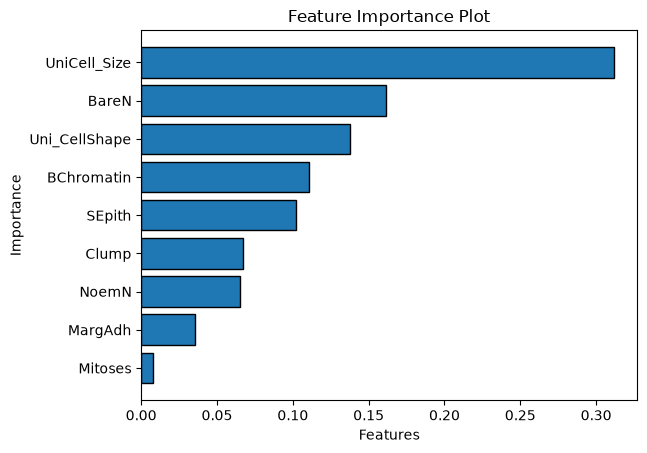

In [14]:
import matplotlib.pyplot as plt
bm = RandomForestClassifier(max_features=2,n_estimators=25,random_state=26)
bm.fit(X,y)
df_imp = pd.DataFrame({'Features':X.columns,
                       'Importance':bm.feature_importances_})
df_imp.sort_values('Importance',inplace=True)
plt.barh(df_imp['Features'], df_imp['Importance'],edgecolor='black')
plt.title('Feature Importance Plot')
plt.xlabel('Features')
plt.ylabel('Importance')
plt.show()

In [ ]:
# exercise on conctrete.csv -> with feature importance